# POST-PHASE13 H2C-B1 — Frozen Localizer-Head Architecture Training Review

## 1. Governance / Adaptive-Development Disclosure

READ-ONLY on rerun. No training, no localizer inference, no segmentation inference — this notebook
only reads on-disk artifacts.

H2C is adaptive VAL development informed by Phase 13 `REVISE_LOCALIZER`, H1 insufficiency,
`H2A_SELECTION_REDESIGN_PARTIAL` and `H2B_OBJECTIVE_REDESIGN_INSUFFICIENT`. The head architecture
and its initialization were frozen **before** training. VAL remains development data. No H2C result
substitutes for final TEST evaluation. TEST remains untouched.


In [1]:

import hashlib, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.figsize"] = (10, 5)

ROOT = Path(r"D:\Softfors\jup")
AUDITS = ROOT / "reports" / "audits"
TABLES = ROOT / "reports" / "tables"
EID = ("post_phase13_h2c_kub_localizer_spatialhead3x3relu_r512_h128_sigmaeq075_"
       "centernetfocal_deploymentbalance_seed42_clean_v3")

def sha(p):
    p = Path(p)
    if not p.is_absolute():
        p = ROOT / p
    return hashlib.sha256(p.read_bytes()).hexdigest()

hist = pd.read_csv(ROOT / "experiments" / EID / "history.csv")
te = json.loads((AUDITS / "post_phase13_h2c_b1_training_evaluation.json").read_text("utf-8"))
sa = json.loads((AUDITS / "post_phase13_h2c_best_checkpoint_standalone_evaluation.json").read_text("utf-8"))
print("Environment OK | epochs:", len(hist))


Environment OK | epochs: 72


## 2. H2C Hypothesis and the Single Changed Axis

**Question.** Can a HEAD-ONLY spatial representation redesign improve heatmap discrimination and
proposal precision while preserving object coverage, holding backbone, target, sigma, loss,
optimizer, scheduler, augmentation, dataset, split, seed, checkpoint selection, proposal policy,
segmentation checkpoints, fusion and segmentation threshold fixed?

**Changed axis (exactly one):** `LOCALIZER_PREDICTION_HEAD_ARCHITECTURE` (`CHANGE_H2C_001`),
including its prospectively frozen initialization.

H2C branches from the **H2A** baseline and **retains the H2A `CenterNetFocalLoss(alpha=2.0,
beta=4.0)` objective** — the H2B soft-target objective is **not** used. H2C must not be described
as "H2B plus a new head".


## 3. H2C Protocol Binding

In [2]:

proto = json.loads((AUDITS / "post_phase13_h2c_protocol_frozen.json").read_text("utf-8"))
print("artifact:", proto["artifact"])
print("status:", proto["status"])
print("protocol SHA:", sha(AUDITS / "post_phase13_h2c_protocol_frozen.json"))
print("experiment_id:", proto["experiment_id"])
print("axis:", proto["purpose"]["changed_axis"])


artifact: POST_PHASE13_H2C_PROTOCOL_FROZEN
status: SUPERVISOR_FROZEN_H2C_HEAD_REDESIGN_READY_FOR_B1_AUTHORIZATION
protocol SHA: 91166259c10a84e9526eda43e83b227cc760a37b8834a4d4a65fe3e5a90ba4b6
experiment_id: post_phase13_h2c_kub_localizer_spatialhead3x3relu_r512_h128_sigmaeq075_centernetfocal_deploymentbalance_seed42_clean_v3
axis: LOCALIZER PREDICTION-HEAD ARCHITECTURE / REPRESENTATION


## 4. RNG-Equivalence Preflight

`RNG_STREAMS_ALREADY_ISOLATED` — the H2C kaiming draws cannot alter TRAIN ordering or augmentation
because those streams are independently owned.


In [3]:

rng = json.loads((AUDITS / "post_phase13_h2c_rng_equivalence_preflight.json").read_text("utf-8"))
e = rng["empirical_equivalence"]
print("classification:", rng["rng_classification"], "| fix required:", rng["execution_fix_required"])
print("TRAIN order equivalent:", e["train_order_equivalent"], "| hash:", e["train_trace_hash_h2a"][:16], "...")
print("VAL order equivalent:", e["val_order_equivalent"], "| hash:", e["val_trace_hash_h2a"][:16], "...")
print("augmentation RNG equivalent:", e["augmentation_rng_equivalent"], "| hash:", e["augmentation_trace_hash_h2a"][:16], "...")
print("python random state equivalent:", e["python_random_state_equivalent"])
print("numpy random state equivalent:", e["numpy_random_state_equivalent"])
print("train/val generator states equivalent:", e["train_generator_state_equivalent"], e["val_generator_state_equivalent"])
print()
print("=== torch global RNG ===")
print("torch_global_rng_state_equivalent:", e["torch_global_rng_state_equivalent"])
print("EXPECTED_INERT_DIFFERENCE_FROM_H2C_KAIMING_DRAWS")
print("  The H2C head performs additional kaiming draws, so the torch GLOBAL RNG state must")
print("  differ. No downstream stream consumes it, so the difference is inert.")


classification: RNG_STREAMS_ALREADY_ISOLATED | fix required: NO
TRAIN order equivalent: True | hash: a7005312d5604601 ...
VAL order equivalent: True | hash: f5e37d7233f6091c ...
augmentation RNG equivalent: True | hash: 53d3baecbd834547 ...
python random state equivalent: True
numpy random state equivalent: True
train/val generator states equivalent: True True

=== torch global RNG ===
torch_global_rng_state_equivalent: False
EXPECTED_INERT_DIFFERENCE_FROM_H2C_KAIMING_DRAWS
  The H2C head performs additional kaiming draws, so the torch GLOBAL RNG state must
  differ. No downstream stream consumes it, so the difference is inert.


## 5. Terminal-Zero Initialization Consequence

`FROZEN_INITIALIZATION_CONSEQUENCE` / `NOT_A_PROTOCOL_DEFECT`.

The terminal 1x1 weights initialize to ZERO, so the hidden 3x3 may receive zero gradient on the
first backward pass until the terminal layer updates. No warmup, no optimizer change, no
initialization change was applied.

**Measured consequence:** the H2A and H2C heads produce *identical initial logits*
(mean −2.197224, max−min exactly 0.0, p = 0.100000) and an identical initial loss of 19.119539.
However H2C's epoch-1 `train_loss` is far higher than H2A's, because H2C learns more slowly at
first. **H2C early-epoch losses are therefore NOT comparable in scale to H2A's.**


In [4]:

print("H2C epoch-1 train_loss:", float(hist.train_loss.iloc[0]))
print("H2C epoch-2 train_loss:", float(hist.train_loss.iloc[1]))
print("(H2A epoch-1 train_loss was 0.001105 — scales are NOT comparable, by design.)")


H2C epoch-1 train_loss: 10.039225600544036
H2C epoch-2 train_loss: 3.6276262757691695
(H2A epoch-1 train_loss was 0.001105 — scales are NOT comparable, by design.)


## 6. H2A → H2C Implementation Diff

In [5]:

imp = json.loads((AUDITS / "post_phase13_h2c_b1_implementation_diff.json").read_text("utf-8"))
print("status:", imp["status"])
print("runner changed lines:", imp["runner_changed_lines"], "| config changed lines:", imp["config_changed_lines"])
print("all machinery probes unchanged:", imp["all_probes_unchanged"])
print("the only scientific change:", imp["the_only_scientific_change"]["change_id"],
      "-", imp["the_only_scientific_change"]["axis"])
print("  H2A head:", imp["the_only_scientific_change"]["h2a_head"])
print("  H2C head:", imp["the_only_scientific_change"]["h2c_head"])
print("  post-freeze initialization change:", imp["the_only_scientific_change"]["post_freeze_initialization_change"])
print("backbone module modified by H2C:", imp["backbone_module_untouched"]["modified_by_h2c"])


status: PASS
runner changed lines: 128 | config changed lines: 30
all machinery probes unchanged: True
the only scientific change: CHANGE_H2C_001 - LOCALIZER_PREDICTION_HEAD_ARCHITECTURE
  H2A head: Conv2d(16 -> 1, kernel_size=1)
  H2C head: Conv2d(16 -> 16, kernel_size=3, padding=1) + ReLU(inplace=False) + Conv2d(16 -> 1, kernel_size=1)
  post-freeze initialization change: NO
backbone module modified by H2C: NO


## 7. Audit-Identity Correction (disclosed defect)

The runner inherited Phase-13 audit payload identity strings. The completed run's start/completion
audit payloads mislabel the run; the **scientific state is correct** (the checkpoint records the
H2C head identity and the correct retained H2A focal objective). Corrected additively.


In [6]:

corr = json.loads((AUDITS / "post_phase13_h2c_b1_audit_identity_correction.json").read_text("utf-8"))
print("classification:", corr["classification"])
print("scientific impact:", corr["scientific_impact"], "| scientific result changed:", corr["scientific_result_changed"])
print("training restarted:", corr["repair_applied"]["training_restarted"])


classification: PERSISTED_REPORTING_DEFECT__AUTHORITATIVE_SCIENTIFIC_STATE_CORRECT
scientific impact: NONE | scientific result changed: NO
training restarted: NO (not warranted - the checkpoint is correct)


## 8. Population and Training Contract

In [7]:

for k, v in te["training_contract"].items():
    print(f"  {k}: {v}")


  TRAIN: 770 FULL_FIELD / 1161 components
  VAL: 103 FULL_FIELD / 152 components
  ROI: EXCLUDED
  manifest: phase4_v3
  taxonomy: kub_size_clean_v3_v1
  input: 512 x 512
  heatmap: 128 x 128
  sigma: 0.75
  loss: CenterNetFocalLoss(alpha=2.0, beta=4.0)
  optimizer: AdamW
  lr: 0.0001
  weight_decay: 0.0001
  scheduler: CosineAnnealingLR(T_max=100)
  batch: 4
  seed: 42
  workers: 0
  max_epochs: 100
  test: forbidden


## 9. Head Architecture Specification

In [8]:

print("head:", te["head"]["name"])
for x in te["head"]["structure"]:
    print("   ", x)
print("hidden width:", te["head"]["hidden_width"])
print("init:", json.dumps(te["head"]["initialization"], indent=1))
print("parameter contract:", json.dumps(te["head"]["parameter_contract"]))


head: SPATIAL_DISCRIMINATIVE_HEAD_3X3_RELU_1X1_V1
    Conv2d(16,16,k=3,p=1)
    ReLU(inplace=False)
    Conv2d(16,1,k=1)
hidden width: 16
init: {
 "conv3x3_weight": "kaiming_normal_(nonlinearity='relu')",
 "conv3x3_bias": 0,
 "conv1x1_weight": "ALL ZERO",
 "conv1x1_bias": "logit(0.1) = -2.1972245773362196",
 "normalization": "NONE",
 "dropout": "NONE",
 "tuned_after_results": "NO"
}
parameter contract: {"old_head_params": 17, "new_head_params": 2337, "whole_model_old": 482449, "whole_model_h2c": 484769}


## 10. Complete Epoch-by-Epoch Table

One completed epoch per row — **all epochs, untruncated, no ellipsis**.


In [9]:

import pandas as _pd
_pd.set_option("display.max_rows", None); _pd.set_option("display.max_columns", None)
_pd.set_option("display.width", 0); _pd.set_option("display.max_colwidth", None)

_ecols = ["epoch", "train_loss", "val_loss", "proposal_pixel_any_hit_precision",
          "tiny_recall90", "overall_recall90", "deployment_balance_hmean",
          "proposal_total_count", "mean_roi_area_fraction", "selection_tuple",
          "is_new_best", "bad_epochs"]
print("=" * 100)
print(f"COMPLETE EPOCH TABLE — {len(hist)} / {len(hist)} rows")
print("=" * 100)
print(hist[_ecols].to_string(index=False))
print()
assert hist.epoch.is_unique and int(hist.epoch.iloc[0]) == 1
assert bool((hist.epoch.diff().dropna() == 1).all())
print(f"CONFIRMED: {len(hist)} contiguous epochs 1..{int(hist.epoch.iloc[-1])}, no duplicates")


COMPLETE EPOCH TABLE — 72 / 72 rows
 epoch  train_loss  val_loss  proposal_pixel_any_hit_precision  tiny_recall90  overall_recall90  deployment_balance_hmean  proposal_total_count  mean_roi_area_fraction                                                                                                                   selection_tuple  is_new_best  bad_epochs
     1   10.039226  5.229574                          0.000000       0.000000          0.000000                  0.000000                     0                0.000000                                                                                    [0.0, 0.0, 0.0, 0.0, -0.0, -5.229573616614709]         True           0
     2    3.627626  3.014969                          0.000000       0.000000          0.000000                  0.000000                     0                0.000000                                                                                   [0.0, 0.0, 0.0, 0.0, -0.0, -3.0149685878020067]         True        

## 11. Loss Curves

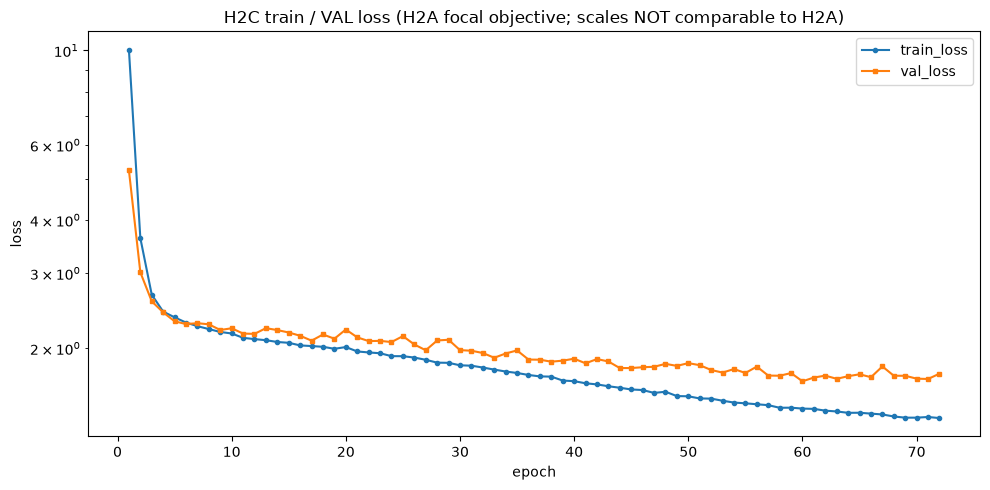

In [10]:

fig, ax = plt.subplots()
ax.plot(hist.epoch, hist.train_loss, marker="o", ms=3, label="train_loss")
ax.plot(hist.epoch, hist.val_loss, marker="s", ms=3, label="val_loss")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("loss")
ax.set_title("H2C train / VAL loss (H2A focal objective; scales NOT comparable to H2A)")
ax.legend(); plt.tight_layout(); plt.show()


## 12. P / tiny90 / overall90 Trajectories

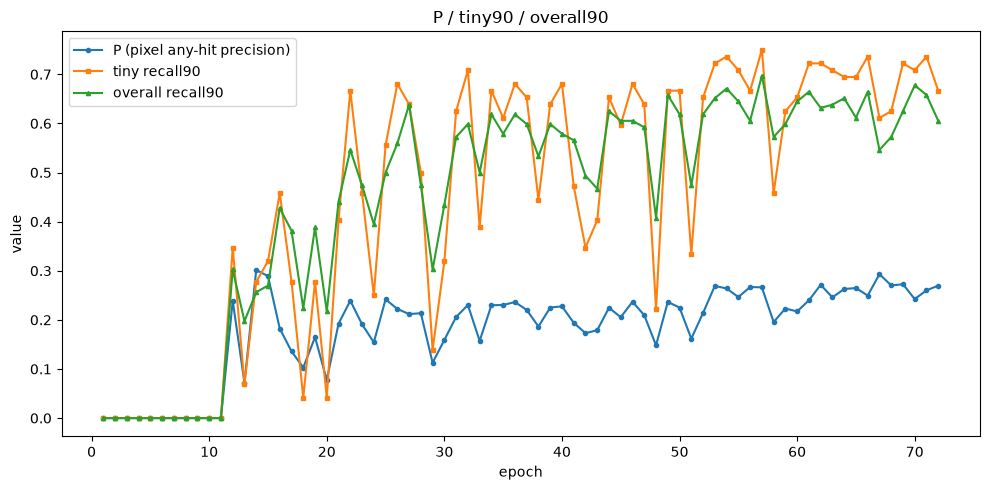

In [11]:

fig, ax = plt.subplots()
ax.plot(hist.epoch, hist.proposal_pixel_any_hit_precision, marker="o", ms=3, label="P (pixel any-hit precision)")
ax.plot(hist.epoch, hist.tiny_recall90, marker="s", ms=3, label="tiny recall90")
ax.plot(hist.epoch, hist.overall_recall90, marker="^", ms=3, label="overall recall90")
ax.set_xlabel("epoch"); ax.set_ylabel("value"); ax.set_title("P / tiny90 / overall90")
ax.legend(); plt.tight_layout(); plt.show()


## 13. Deployment-Balance Trajectory

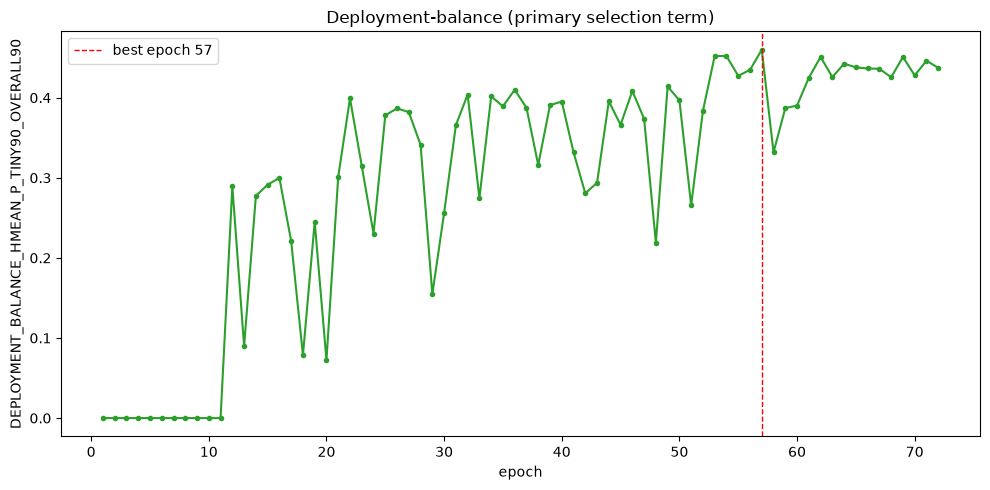

best epoch: 57


In [12]:

fig, ax = plt.subplots()
ax.plot(hist.epoch, hist.deployment_balance_hmean, marker="o", ms=3, color="tab:green")
be = int(hist.loc[hist.is_new_best.astype(bool), "epoch"].iloc[-1])
ax.axvline(be, color="red", ls="--", lw=1, label=f"best epoch {be}")
ax.set_xlabel("epoch"); ax.set_ylabel("DEPLOYMENT_BALANCE_HMEAN_P_TINY90_OVERALL90")
ax.set_title("Deployment-balance (primary selection term)"); ax.legend()
plt.tight_layout(); plt.show()
print("best epoch:", be)


## 14. Proposal Count / Union Area

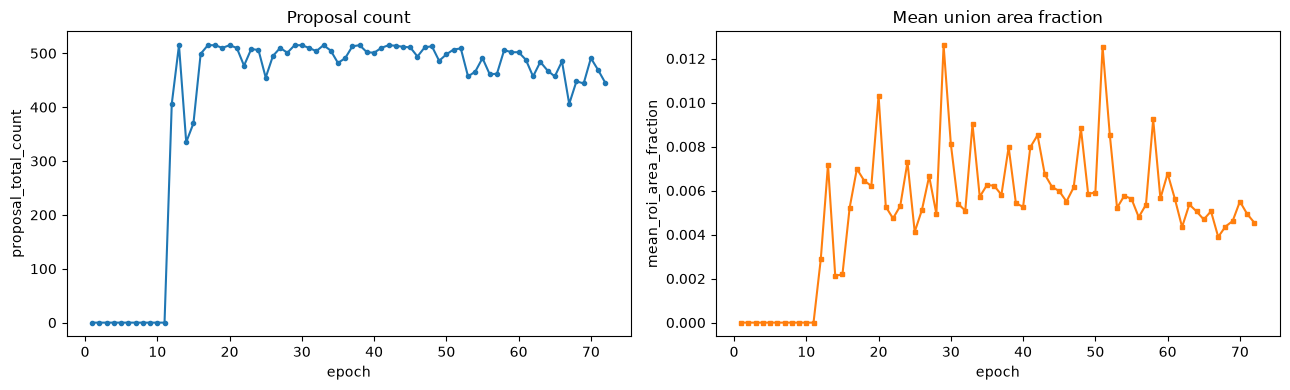

In [13]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(hist.epoch, hist.proposal_total_count, marker="o", ms=3)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("proposal_total_count"); axes[0].set_title("Proposal count")
axes[1].plot(hist.epoch, hist.mean_roi_area_fraction, marker="s", ms=3, color="tab:orange")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("mean_roi_area_fraction"); axes[1].set_title("Mean union area fraction")
plt.tight_layout(); plt.show()


## 15. Score-Distribution Diagnostics

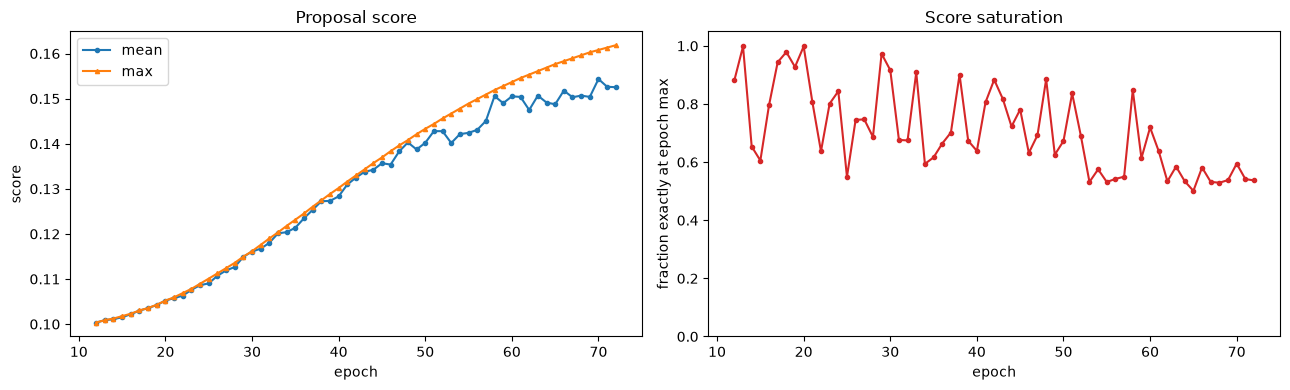

In [14]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(hist.epoch, hist.proposal_score_mean, marker="o", ms=3, label="mean")
axes[0].plot(hist.epoch, hist.proposal_score_max, marker="^", ms=3, label="max")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("score"); axes[0].set_title("Proposal score"); axes[0].legend()
axes[1].plot(hist.epoch, hist.fraction_proposals_exactly_at_epoch_max_score, marker="o", ms=3, color="tab:red")
axes[1].set_ylim(0, 1.05); axes[1].set_xlabel("epoch")
axes[1].set_ylabel("fraction exactly at epoch max"); axes[1].set_title("Score saturation")
plt.tight_layout(); plt.show()


## 16. Checkpoint-Selection Events

In [15]:

best = hist[hist.is_new_best.astype(bool)]
print("new-best epochs:", best.epoch.tolist())
print()
print(hist[["epoch", "deployment_balance_hmean", "is_new_best", "best_epoch_so_far", "bad_epochs"]].tail(12).to_string(index=False))


new-best epochs: [1, 2, 3, 4, 5, 6, 8, 9, 11, 12, 15, 16, 21, 22, 32, 36, 49, 53, 57]

 epoch  deployment_balance_hmean  is_new_best  best_epoch_so_far  bad_epochs
    61                  0.424899        False                 57           4
    62                  0.450895        False                 57           5
    63                  0.425773        False                 57           6
    64                  0.442463        False                 57           7
    65                  0.437875        False                 57           8
    66                  0.436573        False                 57           9
    67                  0.436081        False                 57          10
    68                  0.425556        False                 57          11
    69                  0.450854        False                 57          12
    70                  0.427744        False                 57          13
    71                  0.446246        False                 57  

## 17. Independent Selection Replay

In [16]:

rp = json.loads((AUDITS / "post_phase13_h2c_b1_selection_replay_verification.json").read_text("utf-8"))
print("status:", rp["status"], "| mismatches:", rp["mismatch_count"])
print("best epoch replayed/stored:", rp["replayed"]["best_epoch"], "/", rp["stored"]["best_epoch"])
print("max abs term diff:", rp["max_abs_term_diff"])
print("final bad epochs:", rp["replayed"]["final_bad_epochs"])


status: PASS | mismatches: 0
best epoch replayed/stored: 57 / 57
max abs term diff: 9.8879238130678e-17
final bad epochs: 15


## 18. Standalone Best-Checkpoint Results

In [17]:

m = sa["metrics"]
for k in ("proposal_total_count", "proposal_count_per_image", "proposal_pixel_any_hit_precision",
          "proposal_bbox_any_hit_precision", "tiny_recall90", "overall_recall90",
          "overall_recall50", "any_overlap_recall", "mean_coverage", "mean_proposal_union_area",
          "score_max", "score_iqr", "fraction_exactly_at_max",
          "roc_auc_score_to_pixel_any_hit", "pr_auc_score_to_pixel_any_hit"):
    print(f"  {k}: {m[k]}")
print()
print("head statistics at the selected checkpoint (DESCRIPTIVE ONLY):")
for k, v in sa["head_statistics"].items():
    print(f"  {k}: {v}")


  proposal_total_count: 462
  proposal_count_per_image: 4.485436893203883
  proposal_pixel_any_hit_precision: 0.2662337662337662
  proposal_bbox_any_hit_precision: 0.26406926406926406
  tiny_recall90: 0.75
  overall_recall90: 0.6973684210526315
  overall_recall50: 0.8223684210526315
  any_overlap_recall: 0.8881578947368421
  mean_coverage: 0.8084159294904666
  mean_proposal_union_area: 0.005357889447390801
  score_max: 0.1509026288986206
  score_iqr: 0.004663035273551941
  fraction_exactly_at_max: 0.5497835497835498
  roc_auc_score_to_pixel_any_hit: 0.7564213252751997
  pr_auc_score_to_pixel_any_hit: 0.412665101791798

head statistics at the selected checkpoint (DESCRIPTIVE ONLY):
  hidden_3x3_weight_mean: 0.07307836413383484
  hidden_3x3_weight_std: 0.11414944380521774
  hidden_3x3_weight_min: -0.39343491196632385
  hidden_3x3_weight_max: 0.5020455121994019
  hidden_3x3_fraction_positive: 0.73828125
  hidden_3x3_fraction_negative: 0.26171875
  hidden_3x3_channel_norm_min: 1.5530853271

## 19. Size-Stratified Evidence

In [18]:

st = pd.read_csv(TABLES / "post_phase13_h2c_best_checkpoint_size_stratified.csv")
print(st.to_string(index=False))


stratum  n_components  covered90_count  covered90_rate  covered50_count  covered50_rate  any_overlap_count  any_overlap_rate  mean_coverage  mean_component_pixels
   TINY            72               54        0.750000               57        0.791667                 59          0.819444       0.782983             709.472222
  SMALL            28               20        0.714286               24        0.857143                 27          0.964286       0.867135            1575.964286
 MEDIUM            36               23        0.638889               31        0.861111                 34          0.944444       0.837156            4140.611111
  LARGE            16                9        0.562500               13        0.812500                 15          0.937500       0.755438           23688.500000
    ALL           152              106        0.697368              125        0.822368                135          0.888158       0.808416            4100.572368


## 20. Frozen Difficult Cohorts

Global-empty is reported as `GLOBAL_EMPTY_COMPONENTS_WITHIN_5_FROZEN_IMAGES` — never as
"8 global-empty images".


In [19]:

print("hard_tiny:", json.dumps(sa["metrics"]["hard_tiny"]))
print("global_empty:", json.dumps(sa["metrics"]["global_empty"]))
print("multi_component:", json.dumps(sa["metrics"]["multi_component"]))


hard_tiny: {"n": 15, "covered90": 6, "covered90_rate": 0.4, "any_overlap": 7}
global_empty: {"n": 8, "covered90": 3, "covered90_rate": 0.375, "any_overlap": 4}
multi_component: {"n": 98, "covered90": 67, "covered90_rate": 0.6836734693877551}


## 21. Comparison vs H2A and Phase13

Descriptive single-seed development evidence only. **No winner, no superiority claim, no
significance claim.**


In [20]:

cmp = pd.read_csv(TABLES / "post_phase13_h2c_vs_h2a_vs_phase13_localizer_comparison.csv")
print(cmp.to_string(index=False))


                        quantity  phase13_best_epoch53  h2a_best_epoch83   h2c_best  delta_h2c_minus_h2a  delta_h2c_minus_phase13
            proposal_total_count            494.000000        457.000000 462.000000             5.000000               -32.000000
proposal_pixel_any_hit_precision              0.246964          0.275711   0.266234            -0.009477                 0.019270
 proposal_bbox_any_hit_precision              0.248988          0.273523   0.264069            -0.009454                 0.015081
                   tiny_recall90              0.680556          0.694444   0.750000             0.055556                 0.069444
                overall_recall90              0.598684          0.638158   0.697368             0.059211                 0.098684
                overall_recall50              0.789474          0.822368   0.822368             0.000000                 0.032895
              any_overlap_recall              0.848684          0.875000   0.888158       

## 22. Limitations

1. Single-seed adaptive VAL-development evidence.
2. H2C train/val loss magnitudes are **not** comparable to H2A's: the frozen zero-terminal
   initialization makes H2C learn more slowly at first (identical initial loss of 19.119539, but a
   far higher epoch-1 train_loss). There is no cross-branch loss-trajectory gate.
3. The deployment-balanced rule cannot discriminate epochs before proposals appear.
4. Descriptive comparison only — no statistical superiority claim.
5. No threshold search, no proposal grid, no head-family search, no hidden-width search.
6. Head statistics are descriptive only and never influenced selection.
7. The runner's inherited audit-payload identity strings were corrected additively (see §7);
   scientific state unaffected.
8. TEST remains untouched.


## 23. Explicit Downstream Stop Boundary

**H2C-B1 DOES NOT run downstream segmentation.**

Not authorized and not performed: H2C-B2, UNet/Attention/UNet++/DeepLabV3+ regional evaluation,
H1 selective acceptance, fusion redesign, objective change, another head variant, H3, Phase 14,
TEST access.

**H2C outcome is NOT adjudicated here.**


## 24. Artifact SHA Registry

In [21]:

artifacts = [
    "reports/audits/post_phase13_h2c_protocol_frozen.json",
    "reports/audits/post_phase13_h2c_rng_equivalence_preflight.json",
    "reports/audits/post_phase13_h2c_preexecution_counter_clarification.json",
    "reports/audits/post_phase13_h2c_b1_implementation_diff.json",
    "reports/audits/post_phase13_h2c_b1_training_start.json",
    "reports/audits/post_phase13_h2c_b1_training_completion.json",
    "reports/audits/post_phase13_h2c_b1_audit_identity_correction.json",
    "reports/audits/post_phase13_h2c_b1_selection_replay_verification.json",
    "reports/audits/post_phase13_h2c_best_checkpoint_standalone_evaluation.json",
    "reports/audits/post_phase13_h2c_b1_training_evaluation.json",
    "reports/tables/post_phase13_h2c_best_checkpoint_case_proposals.csv",
    "reports/tables/post_phase13_h2c_best_checkpoint_proposals.csv",
    "reports/tables/post_phase13_h2c_best_checkpoint_component_coverage.csv",
    "reports/tables/post_phase13_h2c_best_checkpoint_size_stratified.csv",
    "reports/tables/post_phase13_h2c_vs_h2a_vs_phase13_localizer_comparison.csv",
    "experiments/" + EID + "/history.csv",
    "checkpoints/" + EID + "/best.pt",
    "checkpoints/" + EID + "/latest.pt",
]
for a in artifacts:
    p = ROOT / a
    print(f"{sha(p) if p.exists() else 'MISSING':64s}  {Path(a).name}")


91166259c10a84e9526eda43e83b227cc760a37b8834a4d4a65fe3e5a90ba4b6  post_phase13_h2c_protocol_frozen.json
aa5a9b7a7a4a39fcaa823ca3ef00f82779af9ae147d037d9c1bc82b86041fdda  post_phase13_h2c_rng_equivalence_preflight.json
5c7152295fbf6a075174fcb928dc296a4503e6b2508a5d94bf4932117d2323a4  post_phase13_h2c_preexecution_counter_clarification.json
bd299f7dcaf350231f0b9c3311b371fe90445f25d0123b97ff20bb668498b0f9  post_phase13_h2c_b1_implementation_diff.json
fd07bfa6a585e783b24700de4abe051143487250f06cc63345c7c6c6dbcdc872  post_phase13_h2c_b1_training_start.json
327d704b7b53fea0cf3f1fd5168759a02d5c65a248d577c4fa2ede7be05b0c3d  post_phase13_h2c_b1_training_completion.json
19b40c50ffdd02f2c6f77af794093669cf0de05254c0af899bd60366adaad5b3  post_phase13_h2c_b1_audit_identity_correction.json
fe2c47209bee3ae9dd676c7b7ae13b4612f7272a2b1aa7b17814db69c46098cb  post_phase13_h2c_b1_selection_replay_verification.json
711768cdda39b8e8e62e4af6e0b1e076f30bf18f3d29c05d393022f7f58df346  post_phase13_h2c_best_check